In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [8]:
mcv=df.isnull().sum()
mcv

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [6]:
print(mcv[mcv>0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [ ]:
➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

In [28]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"]=df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"]=df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

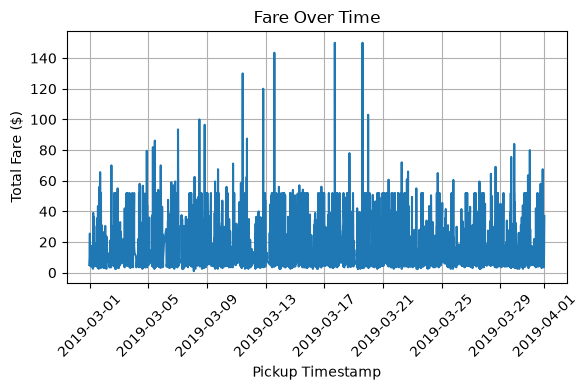

In [65]:
daily_fare=(df.groupby("pickup")["fare"].sum().sort_index())
plt.figure(figsize=(6,4))
plt.plot(daily_fare.index,daily_fare.values)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

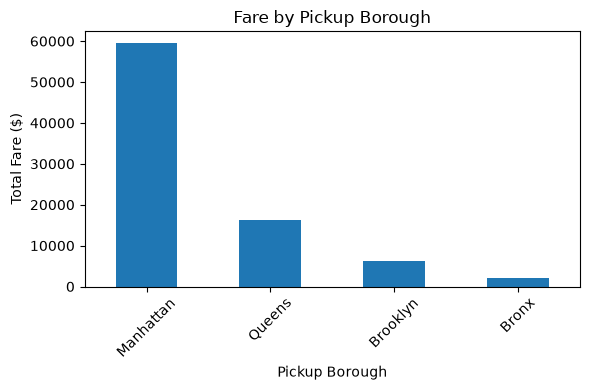

In [67]:
bfare=(df.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False))
plt.figure(figsize=(6,4))
bfare.plot(kind="bar")
plt.title("Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

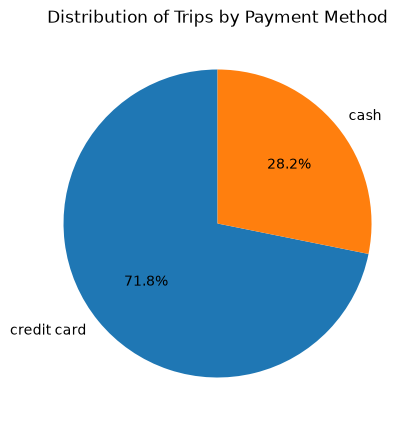

In [95]:
pcounts = df["payment"].value_counts()
plt.figure(figsize=(5,5))
plt.pie(pcounts,labels=pcounts.index,autopct="%1.1f%%",startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.show()

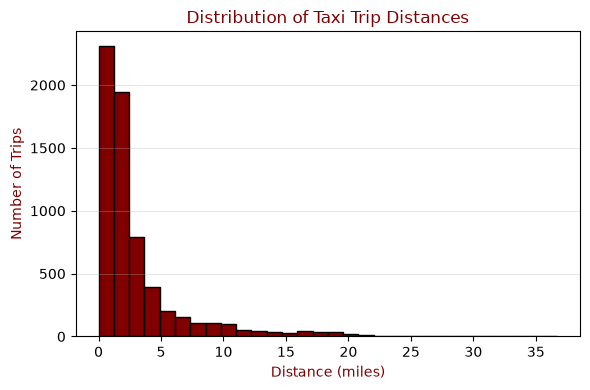

In [90]:
plt.figure(figsize=(6,4))
plt.hist(df["distance"].dropna(),bins=30,edgecolor="black",color="Maroon")
plt.title("Distribution of Taxi Trip Distances",color="Maroon")
plt.xlabel("Distance (miles)",color="Maroon")
plt.ylabel("Number of Trips",color="Maroon")
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 600x400 with 0 Axes>

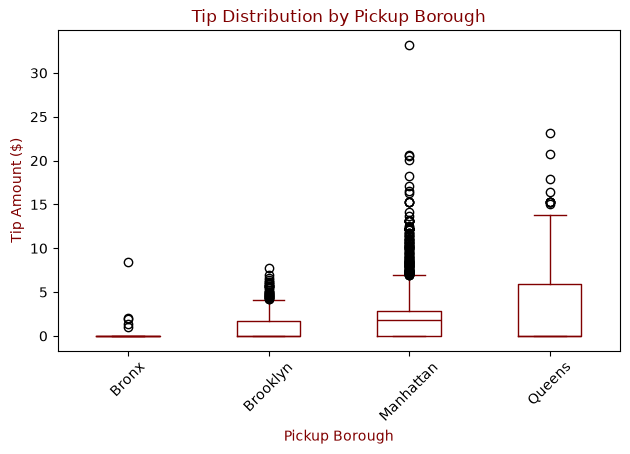

In [84]:
tdata = df.dropna(subset=["pickup_borough", "tip"])
plt.figure(figsize=(6,4))
tdata.boxplot(column="tip",by="pickup_borough",grid=False,color="Maroon")
plt.title("Tip Distribution by Pickup Borough",color="Maroon")
plt.suptitle("")
plt.xlabel("Pickup Borough",color="Maroon")
plt.ylabel("Tip Amount ($)",color="Maroon")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

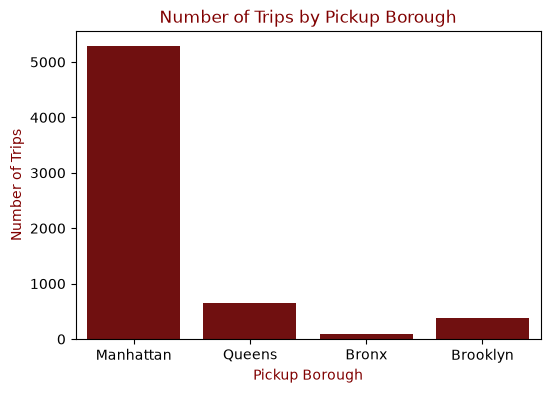

In [76]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="pickup_borough",color="Maroon")
plt.title("Number of Trips by Pickup Borough",color="Maroon")
plt.xlabel("Pickup Borough",color="Maroon")
plt.ylabel("Number of Trips",color="Maroon")
plt.show()

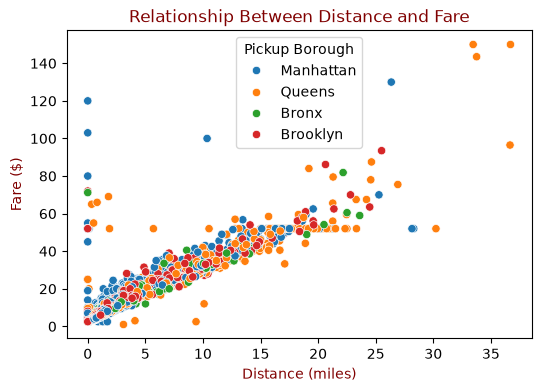

In [79]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Relationship Between Distance and Fare",color="Maroon")
plt.xlabel("Distance (miles)",color="Maroon")
plt.ylabel("Fare ($)",color="Maroon")
plt.legend(title="Pickup Borough")
plt.show()

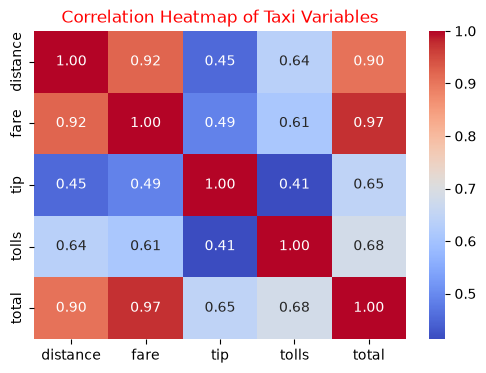

In [82]:
numerical_columns = ["distance", "fare", "tip", "tolls", "total"]
correlation_matrix = df[numerical_columns].corr()
plt.figure(figsize=(6,4))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap of Taxi Variables",color="Maroon")
plt.show()

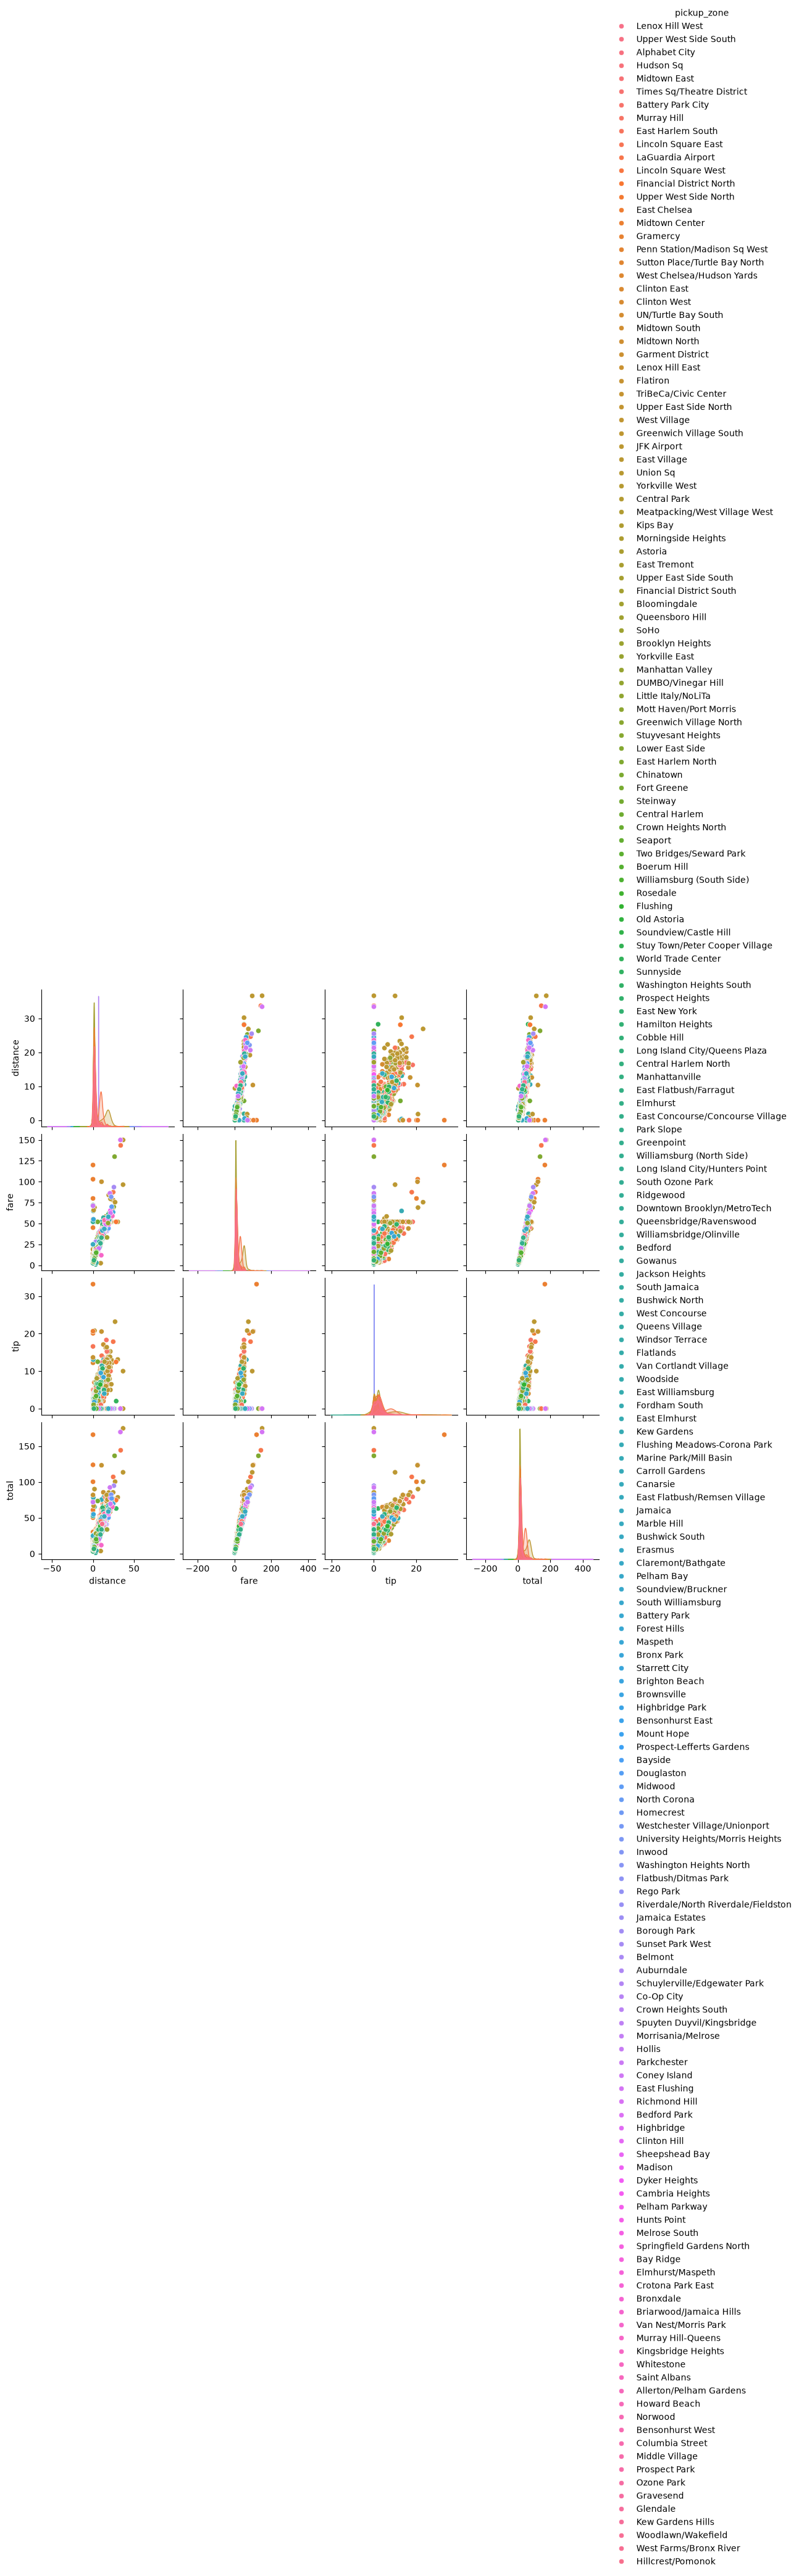

In [97]:
sns.pairplot(df,vars=["distance", "fare", "tip", "total"],hue="pickup_zone")
plt.show()

In [ ]:
Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

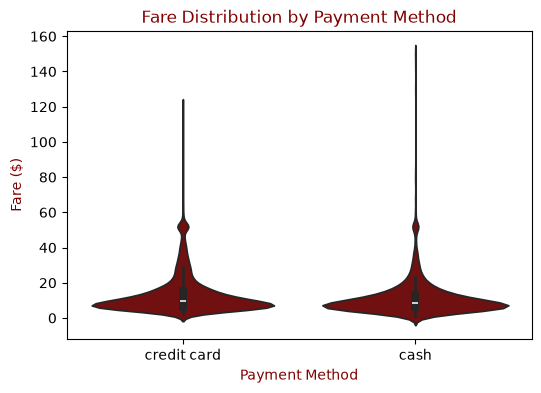

In [87]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df,x="payment",y="fare",color="Maroon")
plt.title("Fare Distribution by Payment Method",color="Maroon")
plt.xlabel("Payment Method",color="Maroon")
plt.ylabel("Fare ($)",color="Maroon")
plt.show()